# Week 2 Day 4 Challenge - scoring the swarm, and a restart partway through a dispatch

The challenge: the lab's dispatcher fans out to the claim agents but never comes back together. Add a `score_run` node after `work_claim` that scores the whole run and puts the scores in the state. Try it with the stand-in first.

The stretch challenge: compile the dispatcher with Day 3's `PostgresSaver` and run it on a thread of its own. Restart the kernel while the claim agents are working, then run the dispatcher again on the same thread with `invoke(None, config)`. Which claims does LangGraph work again?

The dispatcher, the stand-in, the claim agent and the scoring are the lab's, in `week2day4_swarm.py` next to this notebook, with these changes:

| | Lab | Challenge |
|---|---|---|
| The state | `claims` and `results` | The same, and `scores` |
| After `work_claim` | `END` | `score_run`, then `END` |
| The scores | Worked out in the notebook after the run | Worked out by `score_run`, in the graph's output |
| The stand-in | One second for every claim | One, two or three seconds, so the claims finish at different times |
| Decisions | A dict in memory | The same for the challenge; a table in Supabase for the stretch, so a restart doesn't forget them |

A kernel can't be restarted in the middle of a cell in a notebook that runs from top to bottom, so for the stretch the notebook starts the dispatcher as a process of its own (`multiprocessing`, running the module's `main`), kills it partway through and picks the dispatch up itself. Killing the process is what a kernel restart does to the claim agents.

The model is the lab's: GPT-6 Luna on OpenRouter with its reasoning at `low`.

## Setup

In [1]:
import multiprocessing
import time
import uuid

import pandas as pd
import week2day4_swarm as swarm
from IPython.display import Image
from langfuse import get_client
from langfuse.langchain import CallbackHandler
from langgraph.checkpoint.postgres import PostgresSaver

langfuse = get_client()
print("Connected to Langfuse" if langfuse.auth_check() else "No Langfuse keys found")
print(f"{len(swarm.claims)} harder claims")

Connected to Langfuse
25 harder claims


## The challenge: a score_run node

`score_run` takes the whole run's results from the state and scores them. The edge `work_claim → score_run` makes LangGraph wait for every claim agent the dispatcher sent before it runs `score_run`, once. A stand-in's results have no decisions, so it gets only the times.

```python
def score_run(state: Dispatch):
    results = state["results"]
    scores = time_scores(results)
    if all("decision" in result for result in results):
        scores = quality_scores(results) | scores
    return {"scores": scores}
```

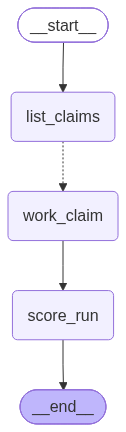

In [2]:
dispatcher = swarm.build_dispatcher(swarm.stand_in)
Image(dispatcher.get_graph().draw_mermaid_png())

### With the stand-in

`swarm.score_runs` keeps the number of results `score_run` saw each time it ran, so we can check it ran once and saw every claim.

In [3]:
rows = {}
for agents in (1, 5, 25):
    swarm.score_runs.clear()
    result = dispatcher.invoke({}, {"max_concurrency": agents})
    rows[f"{agents} at once"] = result["scores"] | {"score_run ran": len(swarm.score_runs), "results it saw": swarm.score_runs[0]}

pd.DataFrame(rows).T.round(2)

,claims,seconds,slowest_claim,seconds_per_claim,score_run ran,results it saw
1 at once,25.0,49.02,3.0,1.96,1.0,25.0
5 at once,25.0,11.00,3.0,1.96,1.0,25.0
25 at once,25.0,3.01,3.0,1.96,1.0,25.0


The lab's flaky stand-in fails the first time it works CLM-1207, and the `RetryPolicy` works it again. The retry happens inside the same step, so `score_run` still runs once, with all 25 results.

In [4]:
tries = {}


def flaky_stand_in(claim_id):
    """The stand-in, failing the first time it works CLM-1207."""
    tries[claim_id] = tries.get(claim_id, 0) + 1
    if claim_id == "CLM-1207" and tries[claim_id] == 1:
        raise Exception("429 Too Many Requests")
    return swarm.stand_in(claim_id)


swarm.score_runs.clear()
result = swarm.build_dispatcher(flaky_stand_in).invoke({}, {"max_concurrency": 25})
print(f"CLM-1207 took {tries['CLM-1207']} tries. score_run ran {len(swarm.score_runs)} time and saw {swarm.score_runs[0]} results.")
pd.Series(result["scores"]).round(2)

CLM-1207 took 2 tries. score_run ran 1 time and saw 25 results.


claims               25.00
seconds               3.41
slowest_claim         3.00
seconds_per_claim     1.96
dtype: float64

### With the claim agents

The same graph with the lab's claim agent, 5 at once, traced in Langfuse. The scores come back in the graph's output, and go to the run's trace as they did in the lab.

In [5]:
swarm.records.use(swarm.MemoryRecords())
swarm.score_runs.clear()
langfuse_handler = CallbackHandler()
dispatcher = swarm.build_dispatcher(swarm.work_claim)
result = dispatcher.invoke({}, {"max_concurrency": 5, "callbacks": [langfuse_handler], "run_name": "Swarm of 5 with score_run"})

for name, value in result["scores"].items():
    langfuse.create_score(trace_id=langfuse_handler.last_trace_id, name=name, value=float(value))
langfuse.flush()

print(f"score_run ran {len(swarm.score_runs)} time and saw {swarm.score_runs[0]} results")
pd.Series(result["scores"]).round(3)

score_run ran 1 time and saw 25 results


decision_accuracy      1.000
accuracy               0.960
cost_of_mistakes     250.500
straight_through       0.760
llm_cost               0.010
claims                25.000
seconds               39.500
slowest_claim         15.822
seconds_per_claim      7.388
dtype: float64

In [6]:
table = pd.DataFrame(result["results"]).sort_values("claim_id")
table["handler"] = table["claim_id"].map(lambda claim_id: swarm.labels[claim_id]["decision"])
table["handler_payout"] = table["claim_id"].map(lambda claim_id: swarm.labels[claim_id]["payout"])
wrong = [not swarm.is_right(row, swarm.labels[row["claim_id"]]) for row in table.to_dict("records")]
table.loc[wrong, ["claim_id", "handler", "decision", "handler_payout", "payout", "rationale"]]

,claim_id,handler,decision,handler_payout,payout,rationale
16,CLM-1217,approve,approve,1335.9,1585.9,Approve the necessary medical treatment for th...


## The stretch: a restart partway through a dispatch

Each dispatch gets a thread of its own in Supabase, in the `lab` schema from Day 3. The process records two things there that outlive it: each start of work on a claim (`swarm_attempts`), and each decision (`swarm_decisions`, one per claim and thread, so a second decision is refused as in the lab).

`kill_partway` starts a dispatch in a process of its own and kills it as soon as a number of claims have finished. `pick_up` then runs the dispatcher on the same thread in this notebook, with `invoke(None, config)` when the thread has a checkpoint. A claim with more than one start was worked again.

In [7]:
connection = swarm.connect()
checkpointer = PostgresSaver(swarm.connect())
checkpointer.setup()


def finished_claims(thread_id):
    """How many claims the dispatch on this thread has finished, in any process."""
    query = "SELECT count(*) AS n FROM swarm_attempts WHERE thread_id = %s AND finished_at IS NOT NULL"
    return connection.execute(query, (thread_id,)).fetchone()["n"]


def kill_partway(worker, limit, agents, durability, finished):
    """Start a dispatch as a process of its own and kill it once `finished` claims are done."""
    thread_id = f"swarm-{worker}-{limit}-{agents}-{durability}-{uuid.uuid4().hex[:6]}"
    process = multiprocessing.get_context("spawn").Process(target=swarm.main, args=(thread_id, worker, limit, agents, durability))
    process.start()
    while finished_claims(thread_id) < finished and process.is_alive():
        time.sleep(0.05)
    process.kill()
    process.join()
    return thread_id


def pick_up(thread_id, worker, limit, agents):
    """Run the dispatcher again on the thread, from its checkpoint if it has one."""
    node, max_concurrency = swarm.dispatch_setup(worker, limit, agents)
    config = {"configurable": {"thread_id": thread_id}, "max_concurrency": max_concurrency}
    saved = checkpointer.get_tuple(config)
    saved_results = sum(channel == "results" for _, channel, _ in saved.pending_writes) if saved else 0
    swarm.records.use(swarm.TableRecords(connection, thread_id))
    swarm.score_runs.clear()
    dispatcher = swarm.build_dispatcher(node, checkpointer)
    result = dispatcher.invoke(None if saved else {}, config, durability="sync")
    return saved, saved_results, result


def worked_again(thread_id):
    """The claims started more than once on the thread."""
    query = """SELECT claim_id FROM swarm_attempts WHERE thread_id = %s
        GROUP BY claim_id HAVING count(*) > 1 ORDER BY claim_id"""
    return [row["claim_id"] for row in connection.execute(query, (thread_id,)).fetchall()]


def restart(worker, limit, agents, durability, finished=8):
    """Kill a dispatch partway, pick it up, and report what happened."""
    thread_id = kill_partway(worker, limit, agents, durability, finished)
    done_before = finished_claims(thread_id)
    saved, saved_results, result = pick_up(thread_id, worker, limit, agents)
    again = worked_again(thread_id)
    return {
        "worker": worker,
        "agents at once": f"{agents} ({limit})",
        "durability": durability,
        "finished before the kill": done_before,
        "results saved": saved_results,
        "picked up with": "invoke(None, config)" if saved else "nothing saved: invoke({}, config)",
        "worked again": len(again),
        "results at the end": len(result["results"]),
        "score_run ran": len(swarm.score_runs),
        "claims worked again": ", ".join(claim_id[-2:] for claim_id in again),
        "thread": thread_id,
        "scores": result["scores"],
    }

### With the stand-in

Four restarts, each killed once 8 claims have finished:

- 5 at once with `max_concurrency`, as in the lab, saving after each step (`durability="sync"`, as in the product)
- 25 at once, the same way
- 5 at once with a gate: every claim starts, and a semaphore lets 5 work at a time
- 5 at once, saving only when the run ends (`durability="exit"`)

In [8]:
stand_in_runs = [
    restart("stand-in", "cap", 5, "sync"),
    restart("stand-in", "cap", 25, "sync"),
    restart("stand-in", "gate", 5, "sync"),
    restart("stand-in", "cap", 5, "exit"),
]
pd.DataFrame(stand_in_runs).drop(columns=["scores", "thread"])

,worker,agents at once,durability,finished before the kill,results saved,picked up with,worked again,results at the end,score_run ran,claims worked again
0,stand-in,5 (cap),sync,9,0,"invoke(None, config)",13,25,1,"01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12..."
1,stand-in,25 (cap),sync,9,8,"invoke(None, config)",17,25,1,"01, 02, 04, 05, 07, 08, 11, 12, 14, 15, 17, 18..."
2,stand-in,5 (gate),sync,9,9,"invoke(None, config)",5,25,1,"08, 11, 12, 13, 14"
3,stand-in,5 (cap),exit,9,0,"nothing saved: invoke({}, config)",12,25,1,"01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12"


### What LangGraph saves, and when

LangGraph saves a claim agent's result as a pending write on the step's checkpoint when that agent finishes, and `invoke(None, config)` works only the claims with no saved result. Yet the first run above saved none, though 8 claims had finished.

The reason is in how the synchronous graph runs: the nodes and the saving of their results share one thread pool of `max_concurrency` threads (LangGraph 1.2's `BackgroundExecutor`, built from the config). All 25 claims go into that pool at the start of the step, so with 5 threads the save of a finished claim waits in the queue behind the claims still to start. Killed partway, the run had saved nothing, and every claim it had started is worked again.

With 25 at once every claim has a thread, so a finished claim's thread is free to save it straight away; only the claims still working are worked again. The gate gets the same with 5 agents: `max_concurrency` is above the number of claims, so there are threads to save, and a semaphore keeps the agents to 5. With `durability="exit"` nothing is saved until the run ends, so there is no checkpoint to pick up and the dispatch starts again.

### With the claim agents

The same restart with the claim agents: 5 at once with `max_concurrency`, then with the gate. A claim worked again repeats its model calls. If its agent had recorded a decision before the kill, the second agent's decision is refused by `swarm_decisions`, and the result is the first decision.

In [9]:
agent_runs = [restart("agent", "cap", 5, "sync"), restart("agent", "gate", 5, "sync")]
pd.DataFrame(agent_runs).drop(columns=["scores", "thread"])

,worker,agents at once,durability,finished before the kill,results saved,picked up with,worked again,results at the end,score_run ran,claims worked again
0,agent,5 (cap),sync,8,0,"invoke(None, config)",13,25,1,"01, 02, 03, 04, 05, 06, 07, 08, 09, 10, 11, 12..."
1,agent,5 (gate),sync,8,7,"invoke(None, config)",6,25,1,"06, 07, 09, 11, 12, 13"


In [10]:
def refused(thread_id):
    """Claims whose decision was recorded before a later start of work on them, so a later agent's decision was refused."""
    query = """SELECT DISTINCT d.claim_id FROM swarm_decisions d JOIN swarm_attempts a
        ON a.thread_id = d.thread_id AND a.claim_id = d.claim_id AND a.started_at > d.recorded_at
        WHERE d.thread_id = %s ORDER BY d.claim_id"""
    return [row["claim_id"] for row in connection.execute(query, (thread_id,)).fetchall()]


pd.DataFrame(
    {
        "agents at once": run["agents at once"],
        "worked again": run["worked again"],
        "decided before the kill, worked again": len(refused(run["thread"])),
        "accuracy": run["scores"]["accuracy"],
        "model cost of the results": run["scores"]["llm_cost"],
        "seconds of the results": run["scores"]["seconds"],
    }
    for run in agent_runs
).round(3)

,agents at once,worked again,"decided before the kill, worked again",accuracy,model cost of the results,seconds of the results
0,5 (cap),13,10,0.84,0.009,21.883
1,5 (gate),6,2,0.84,0.010,41.681


## What I found

**The challenge.** `score_run` ran once in every dispatch, after every claim agent, and saw all 25 results: with 1, 5 and 25 at once, and when the `RetryPolicy` worked CLM-1207 a second time. A retry happens inside the step, so it never brings `score_run` forward. With the claim agents 5 at once, the scores in the state were a decision accuracy of 1.00 and an accuracy of 0.96, with mistakes costing $250.50, for $0.010 in 40 seconds. The one miss was CLM-1217, paid $1,585.90 against the handler's $1,335.90. The lab's own run of 5 scored 0.84 in 44 seconds: accuracy moves from run to run, as the lab says.

**The stretch: which claims does LangGraph work again?** Every claim without a saved result. In principle that is only the claims still working at the restart, and with 25 at once that is close to what happened: 8 of the 9 finished results were saved (the ninth was still being saved when the process was killed) and the 17 claims without one were worked again. But with the lab's `max_concurrency=5`, no result at all was saved before the kill, though 9 claims had finished, so every claim the run had started, 13 of them, was worked again. LangGraph's synchronous graph saves results on the same thread pool that runs the nodes, `max_concurrency` threads, and all 25 claims are queued on it at the start of the step, so a finished claim's save waits behind the claims still to start. Letting every claim start (`max_concurrency` above the number of claims) and holding the agents to 5 with a semaphore fixed it: all 9 finished results were saved and only the 5 claims still working were worked again. With `durability="exit"` there was no checkpoint at all, and the dispatch started again from the beginning.

**What it costs with real agents.** With `max_concurrency=5`, 13 claims were worked again after the restart, and 10 of them had already recorded their decision before the kill. Their second agents repeated every model call, and their decisions were refused by the decisions table, so each claim kept its first decision. With the gate, 6 claims were worked again (the 5 still working, and one whose result was still being saved at the kill) and 2 of them had decided before the kill. The lab's decisions are a dict in memory, which a kernel restart empties, so in the lab those claims would have been decided a second time, perhaps differently: its "decisions are final" holds only while the kernel lives. (The times in the last table run from the first result to the last across both processes, so they don't compare with a run that wasn't stopped.)

**For the product.** UnderCover's product gives each claim its own thread, as the lab's last note says, so a claim's work is saved as it goes whatever the dispatcher does, and the backend refuses a second decision or payment. A dispatcher that is itself checkpointed, like this one, should not rely on `max_concurrency` to limit its agents: a semaphore inside the worker keeps the limit without holding back the saves. I didn't try the asynchronous graph.

**Cost.** The lab and this notebook, which I ran three times while building it, cost $0.11 on OpenRouter in all. LangGraph 1.2.12 and langgraph-checkpoint-postgres 3.1.2.